CRS: EPSG:4326
Resolution: (0.0002777777777778146, 0.0002777777777778146)


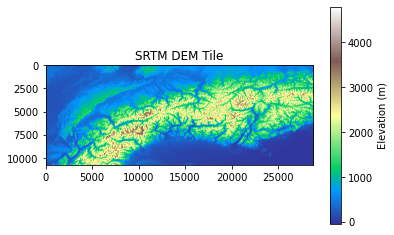

In [1]:
import pandas as pd
import numpy as np
import rasterio
import matplotlib.pyplot as plt
import rioxarray as rxr

path = "data_raw/output_SRTMGL1.tif"  

with rasterio.open(path) as src:
    dem = src.read(1)
    print("CRS:", src.crs)
    print("Resolution:", src.res)

plt.imshow(dem, cmap="terrain")
plt.colorbar(label="Elevation (m)")
plt.title("SRTM DEM Tile")
plt.show()

### Clip DEM to Study Area

In [2]:
dem = rxr.open_rasterio("data_raw/output_SRTMGL1.tif")

dem_clip = dem.rio.clip_box(
    minx=5,
    miny=45,
    maxx=13,
    maxy=48
)

dem_clip.rio.to_raster("data_processed/dem_clipped.tif")

###  Resample to 1 km Grid

In [3]:
dem_1km_res = dem_clip.rio.reproject(
        dem_clip.rio.crs,
        resolution=0.01
)
dem_1km_res.rio.to_raster("data_processed/dem_1km_res.tif")

In [4]:
# CHECKS
dem_1km = rxr.open_rasterio("data_processed/dem_1km_res.tif")
print(dem_1km.shape)

(1, 301, 801)


In [5]:
# remove band dimension
dem_1km_res = dem_1km_res.squeeze()

# replace SRTM nodata values
dem_1km_res = dem_1km_res.where(dem_1km_res != -32768)

print("Min:", float(dem_1km_res.min()))
print("Max:", float(dem_1km_res.max()))


Min: -8.0
Max: 4599.0


### Terrain Features

In [6]:
from xrspatial import slope,aspect

dem = rxr.open_rasterio("data_processed/dem_1km_res.tif")
dem = dem.squeeze() 

# important as as of now system thinks 1 meter = 1 deg
dem_metric = dem_1km_res.rio.reproject("EPSG:3857")

In [7]:
# Computing slope
slope_map = slope(dem_metric)
slope_map

<xarray.DataArray 'slope' (y: 410, x: 751)> Size: 1MB
array([[       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan, 0.5507333 , 0.49836558, ..., 1.4353637 ,        nan,
               nan],
       [       nan, 0.64966017, 0.83665717, ..., 1.2426729 ,        nan,
               nan],
       ...,
       [       nan, 0.07865024, 0.15660468, ..., 0.        ,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]], dtype=float32)
Coordinates:
  * x            (x) float64 6kB 5.572e+05 5.584e+05 ... 1.446e+06 1.448e+06
  * y            (y) float64 3kB 6.106e+06 6.105e+06 ... 5.622e+06 5.621e+06
    band         int32 4B 1
    spatial_ref  int32 4B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    _FillValue:     -32768.0

In [8]:
# Computing Aspect
aspect_map = aspect(dem_metric)
aspect_map

<xarray.DataArray 'aspect' (y: 410, x: 751)> Size: 1MB
array([[      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       [      nan, 298.8108 , 308.1183 , ...,  90.     ,       nan,
              nan],
       [      nan, 211.32869, 208.41266, ...,  88.8876 ,       nan,
              nan],
       ...,
       [      nan, 237.52881, 254.35776, ...,  -1.     ,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan],
       [      nan,       nan,       nan, ...,       nan,       nan,
              nan]], dtype=float32)
Coordinates:
  * x            (x) float64 6kB 5.572e+05 5.584e+05 ... 1.446e+06 1.448e+06
  * y            (y) float64 3kB 6.106e+06 6.105e+06 ... 5.622e+06 5.621e+06
    band         int32 4B 1
    spatial_ref  int32 4B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0
    _FillValue:     -32768.0

In [9]:
# Terrain Ruggedness
from scipy.ndimage import generic_filter

def tri(window):
    center = window[len(window)//2]
    return np.mean(np.abs(window - center))

tri_map = generic_filter(dem_metric.values, tri, size=3)

In [10]:
# reconverting to xarray to store and display
import xarray as xr

tri_map = xr.DataArray(
    tri_map,
    coords=dem_metric.coords,
    dims=dem_metric.dims
)

In [11]:
# save files
slope_map.rio.to_raster("data_processed/slope.tif")
aspect_map.rio.to_raster("data_processed/aspect.tif")
tri_map.rio.to_raster("data_processed/tri.tif")

In [12]:
# Comprehensive Summary
print("DEM stats:")
print("Min:", float(dem_1km_res.min()))
print("Max:", float(dem_1km_res.max()))
print("Mean:", float(dem_1km_res.mean()))

print("\nSlope stats:")
print("Min:", float(slope_map.min()))
print("Max:", float(slope_map.max()))
print("Mean:", float(slope_map.mean()))

print("\nAspect stats:")
print("Min:", float(aspect_map.min()))
print("Max:", float(aspect_map.max()))

print("\nTRI stats:")
print("Min:", float(tri_map.min()))
print("Max:", float(tri_map.max()))


DEM stats:
Min: -8.0
Max: 4599.0
Mean: 962.67724609375

Slope stats:
Min: 0.0
Max: 36.384098052978516
Mean: 5.416906356811523

Aspect stats:
Min: -1.0
Max: 359.9825439453125

TRI stats:
Min: 0.0
Max: 978.7777709960938


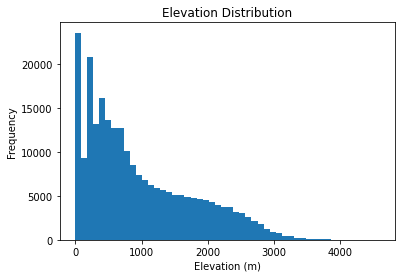

In [13]:
# EDA for elevation distribution

plt.hist(dem_1km_res.values.flatten(), bins=50)
plt.title("Elevation Distribution")
plt.xlabel("Elevation (m)")
plt.ylabel("Frequency")
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

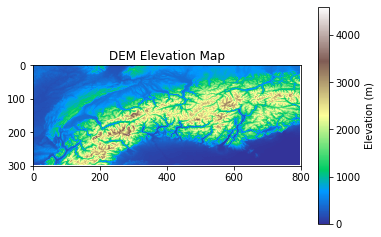

In [14]:
# Spatial map for Elevation
dem_1km_res = dem_1km_res.squeeze()
plt.imshow(dem_1km_res, cmap="terrain")
plt.colorbar(label="Elevation (m)")
plt.title("DEM Elevation Map")
plt.show

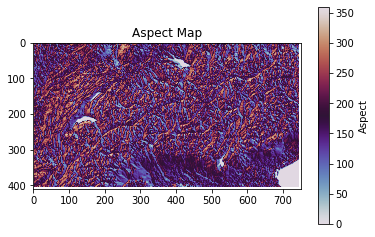

In [15]:
# Spatial map for Aspect
plt.imshow(aspect_map, cmap="twilight")
plt.colorbar(label="Aspect")
plt.title("Aspect Map")
plt.show()


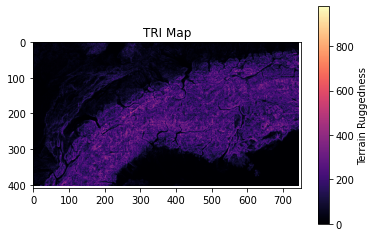

In [16]:
# For TRI 
plt.imshow(tri_map, cmap="magma")
plt.colorbar(label="Terrain Ruggedness")
plt.title("TRI Map")
plt.show()

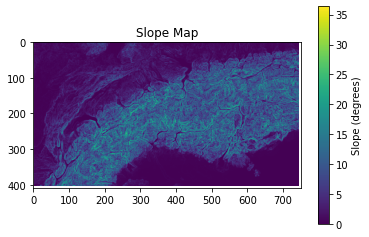

In [17]:
# For Slope
plt.imshow(slope_map, cmap="viridis")
plt.colorbar(label="Slope (degrees)")
plt.title("Slope Map")
plt.show()

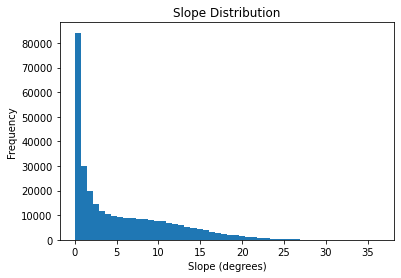

In [18]:
# Hist for Slope
plt.hist(slope_map.values.flatten(), bins=50)
plt.title("Slope Distribution")
plt.xlabel("Slope (degrees)")
plt.ylabel("Frequency")
plt.show()


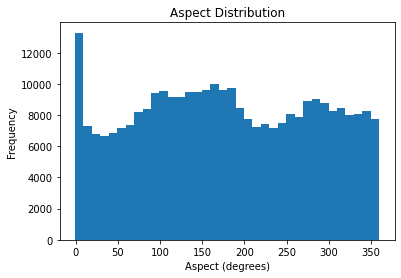

In [19]:
# Hist for Aspect
plt.hist(aspect_map.values.flatten(), bins=36)
plt.title("Aspect Distribution")
plt.xlabel("Aspect (degrees)")
plt.ylabel("Frequency")
plt.show()


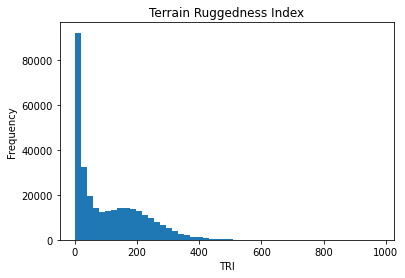

In [20]:
# Hist for Terrain Ruggedness
plt.hist(tri_map.values.flatten(), bins=50)
plt.title("Terrain Ruggedness Index")
plt.xlabel("TRI")
plt.ylabel("Frequency")
plt.show()


In [23]:
# checking shapes before computing correlation matrix
print("DEM: ",dem_1km_res.shape)
print("Slope: ",slope_map.shape)
print("Aspect:",aspect_map.shape)
print("TRI: ",tri_map.shape)

DEM:  (301, 801)
Slope:  (410, 751)
Aspect: (410, 751)
TRI:  (410, 751)


In [24]:
slope_map = slope_map.rio.reproject_match(dem_1km_res)
aspect_map = aspect_map.rio.reproject_match(dem_1km_res)
tri_map = tri_map.rio.reproject_match(dem_1km_res)

In [25]:
print("DEM: ",dem_1km_res.shape)
print("Slope: ",slope_map.shape)
print("Aspect:",aspect_map.shape)
print("TRI: ",tri_map.shape)

DEM:  (301, 801)
Slope:  (301, 801)
Aspect: (301, 801)
TRI:  (301, 801)


In [26]:

df = pd.DataFrame({
    "elevation": dem_1km_res.values.flatten(),
    "slope": slope_map.values.flatten(),
    "aspect": aspect_map.values.flatten(),
    "tri": tri_map.values.flatten()
})

df = df.dropna()

print(df.corr())


           elevation     slope    aspect       tri
elevation   1.000000  0.641867  0.056405  0.720728
slope       0.641867  1.000000  0.060635  0.880162
aspect      0.056405  0.060635  1.000000  0.057206
tri         0.720728  0.880162  0.057206  1.000000
